# Piloto FinBERT v3: Comparativa Estructurada de Técnicas de Sentimiento por Ticker

Este notebook compara **en igualdad de condiciones** sobre **150 noticias largas de Silver** (`umbral = 0.40`, guardando `P_pos`, `P_neg`, `P_neu`) todas las arquitecturas evaluadas para asignar sentimiento a un **ticker objetivo (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`)**.

---

## Diccionario de Técnicas Evaluadas

| Familia | Técnica | Qué texto recibe el modelo | Cómo calcula la nota |
| :--- | :--- | :--- | :--- |
| **1. Baselines** | `REGEX_OLD_V1` | `Titular + frases ±1` cortadas con regex simple (sin abreviaturas ni poda) | 1 pase FinBERT |
| **1. Baselines** | `SPACY_S1B` | `Titular [SEP] frases ±1` segmentadas con `spaCy` + poda *boilerplate* | 1 pase FinBERT |
| **1. Baselines** | `SPACY_S0` | `Titular [SEP] solo frases del banco` segmentadas con `spaCy` + poda | 1 pase FinBERT |
| **2. Regex (`base_nlp`)** | `RE_V1_PODA` | `Titular [SEP] frases ±1` con Regex mejorada (protege `J.P.`, `Inc.`, meses) + poda | 1 pase FinBERT |
| **2. Regex (`base_nlp`)** | `RE_V0_PODA` | `Titular [SEP] solo frases del banco` (ventana `0`) + poda | 1 pase FinBERT |
| **2. Regex (`base_nlp`)** | `RE_TIT_GATE` | **Titular condicional:** solo incluye el titular si nombra al banco objetivo + frases ventana `0` | 1 pase FinBERT |
| **2. Regex (`base_nlp`)** | `RE_ADAPTATIVA` | Ventana `±1` en mono-ticker (podando competidores) y `0` en multi-ticker + titular condicional | 1 pase FinBERT |
| **2. Regex (`base_nlp`)** | `RE_FRASE_MEDIA` | Lista individual de frases del banco (con titular condicional) | 1 pase por frase; media simple de `(P_pos, P_neg, P_neu)` |
| **2. Regex (`base_nlp`)** | `RE_FRASE_PONDERADA` | Misma lista individual de frases del banco | Media ponderada por convicción $w_i = (1 - P_{	ext{neu}, i})^2$ |
| **3. Aspecto (ABSA)** | `ABSA_DEBERTA_BASE` | Par `(texto RE_TIT_GATE, nombre del banco)` en `deberta-v3-base-absa-v1.1` | Atención condicionada al banco |
| **3. Aspecto (ABSA)** | `ENSAMBLE_FB_ABSA` | Combina `RE_FRASE_PONDERADA` + `ABSA_DEBERTA_BASE` | Media 50/50 de probabilidades |
| **3. Aspecto (ABSA)** | `ENSAMBLE_FB_ABSA_ALT_B` | Mismo ensamble + filtro determinista de neutralidad (calendarios, mandatos IPO, rol analista) | Regla `0.0` si es evento neutro; si no, ensamble |
| **4. LLM (`.env`)** | `GEMINI_LLM` | `Titular + contexto RE_ADAPTATIVA` + `ticker` objetivo en **Gemini API** (`GEMINI_API_KEY` en `.env`) | *System Prompt* financiero + batching JSON (15 noticias/llamada) |

## 1. Configuración, Credenciales (`.env`) y Carga de Modelos

In [1]:
import asyncio, importlib, os, re, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import torch
from pydantic import BaseModel, Field
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DebertaV2Tokenizer

curr = Path.cwd()
PROJ_ROOT = next((p for p in [curr, *curr.parents] if (p / "pyproject.toml").exists()), curr)
for p in (PROJ_ROOT / "src", PROJ_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import config.settings as _settings_mod
importlib.reload(_settings_mod)
import articulos.models.base_nlp as _base_nlp_mod
importlib.reload(_base_nlp_mod)

from config.settings import settings
from dependencies.dependencies import get_compactor, get_storage_repository
from articulos.models.base_nlp import BaseProcesadorArticulo
from shared.tickets import ALIAS_BANCOS, BOILERPLATE_SECTOR_PATTERNS

UMBRAL_NEUTRO = 0.40
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Credenciales de Gemini leídas desde .env (vía Pydantic Settings o variable de entorno)
GEMINI_API_KEY = (settings.gemini_api_key or os.getenv("GEMINI_API_KEY", "")).strip()
GEMINI_MODEL = (settings.gemini_model or os.getenv("GEMINI_MODEL", "gemini-3.1-flash-lite")).strip()

# Carga de modelos locales (spaCy para baseline, FinBERT y DeBERTa-ABSA)
nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])

tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
finbert = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(DEVICE).eval()
LBL = {v.lower(): k for k, v in finbert.config.id2label.items()}
I_POS, I_NEG, I_NEU = LBL["positive"], LBL["negative"], LBL["neutral"]

ABSA_HF_ID = "yangheng/deberta-v3-base-absa-v1.1"
absa_tokenizer = DebertaV2Tokenizer.from_pretrained(ABSA_HF_ID)
absa_model = AutoModelForSequenceClassification.from_pretrained(ABSA_HF_ID).to(DEVICE).eval()
LBL_ABSA = {v.lower(): k for k, v in absa_model.config.id2label.items()}
A_POS, A_NEG, A_NEU = LBL_ABSA["positive"], LBL_ABSA["negative"], LBL_ABSA["neutral"]

print(f"[OK] PROJ_ROOT: {PROJ_ROOT} | DEVICE: {DEVICE} | UMBRAL_NEUTRO: {UMBRAL_NEUTRO}")
print(f"[OK] Modelos locales listos -> FinBERT: {finbert.config.id2label} | DeBERTa-ABSA: {absa_model.config.id2label}")
print(f"[OK] Gemini API -> Key configurada: {'SÍ' if GEMINI_API_KEY else 'NO (añade GEMINI_API_KEY en .env)'} | Modelo: {GEMINI_MODEL}")

c:\proyectos\TFM-Master\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 327.20it/s]
c:\proyectos\TFM-Master\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 267.28it/s]

[OK] PROJ_ROOT: c:\proyectos\TFM-Master | DEVICE: cpu | UMBRAL_NEUTRO: 0.4
[OK] Modelos locales listos -> FinBERT: {0: 'positive', 1: 'negative', 2: 'neutral'} | DeBERTa-ABSA: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
[OK] Gemini API -> Key configurada: SÍ | Modelo: gemini-2.5-flash


## 2. Carga de Muestra Alineada (`150` Noticias de Silver) y Ground Truth

In [2]:
CSV_GT = PROJ_ROOT / "scratch" / "finbert_pilot_v3_revision_manual.csv"

async def cargar_muestra_alineada(key="processed/huggingface/categorized_checkpoint.parquet", n=150):
    local_ckpt = PROJ_ROOT / "data" / "silver_categorized_checkpoint.parquet"
    local_backup = PROJ_ROOT / "data" / "processed_multisource_bancos_2010_2023.parquet"
    compact = get_compactor()
    if local_ckpt.exists():
        df = pd.DataFrame(compact.decompact(local_ckpt.read_bytes()))
    else:
        repo = get_storage_repository()
        try:
            try:
                df = pd.DataFrame(compact.decompact(await repo.get(key)))
            except Exception:
                raw = local_backup.read_bytes() if local_backup.exists() else await repo.get("processed/huggingface/multisource_bancos_2010_2023.parquet")
                df = pd.DataFrame(compact.decompact(raw))
        finally:
            await repo.close()
    if "article" not in df.columns and "process_text" in df.columns:
        df["article"] = df["process_text"]

    if CSV_GT.exists():
        gt = pd.read_csv(CSV_GT)
        lkp = df.drop_duplicates(subset=["ticker", "title"]).set_index(["ticker", "title"])
        aligned = []
        for _, r in gt.iterrows():
            k = (r["ticker"], r["titular"])
            if k in lkp.index:
                row_d = lkp.loc[k].to_dict()
                row_d["ticker"], row_d["title"] = k
                aligned.append(row_d)
        if len(aligned) == len(gt):
            return pd.DataFrame(aligned).reset_index(drop=True), gt

    if "is_ruido" in df.columns:
        df = df[~df["is_ruido"]]
    df = df[df["article"].fillna("").str.len() > 1500]
    sub = df.sample(n=min(n, len(df)), random_state=42).reset_index(drop=True)
    return sub, None

df_silver, df_gt = await cargar_muestra_alineada(n=150)
print(f"[OK] Muestra cargada: {len(df_silver)} artículos | Ground Truth: {len(df_gt) if df_gt is not None else 'No disponible'}")

 INFO     | 2026-11-23 11:44:02.662974 | ParquetCompactor | Descompactados 27,350 registros desde buffer Parquet (28,688,978 bytes).
[OK] Muestra cargada: 150 artículos | Ground Truth: No disponible


## 3. Extractores de Texto e Inspección Visual de Cómo Funciona Cada Uno

Antes de lanzar los modelos, definimos todos los extractores y mostramos **un ejemplo real** para ver qué texto exacto recibe cada técnica.

In [3]:
REGEX_OLD = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])")
NOMBRE_CANONICO = {
    "JPM": "JPMorgan Chase",
    "BAC": "Bank of America",
    "WFC": "Wells Fargo",
    "C": "Citigroup",
    "GS": "Goldman Sachs",
    "MS": "Morgan Stanley",
}

def extraer_regex_antigua(titular, cuerpo, ticker, ventana=1):
    cuerpo = (cuerpo or "").strip()
    if not cuerpo:
        return titular.strip(), False
    oraciones = [s.strip() for s in REGEX_OLD.split(cuerpo) if s.strip()]
    aliases = ALIAS_BANCOS.get(ticker, [ticker.lower()])
    pat = re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)
    hits = [i for i, s in enumerate(oraciones) if pat.search(s)]
    if not hits:
        return f"{titular.strip()}. {oraciones[0] if oraciones else ''}".strip(), False
    idx = sorted({j for i in hits for j in range(i - ventana, i + ventana + 1) if 0 <= j < len(oraciones)})
    return f"{titular.strip()}. " + " ".join(oraciones[i] for i in idx), True

def podar_boilerplate_v2(cuerpo):
    out = cuerpo
    for bp in BOILERPLATE_SECTOR_PATTERNS:
        out = re.sub(bp + r".*?(\n|$)", "", out, flags=re.IGNORECASE)
    out = re.sub(r"^.*Free Stock Analysis Report.*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    out = re.sub(r"^.*(Zacks Investment Research|To read this article on Zacks).*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    return out

def extraer_spacy_v2(titular, cuerpo, ticker, ventana=1):
    cuerpo = podar_boilerplate_v2((cuerpo or "").strip())
    if not cuerpo:
        return titular.strip(), False
    oraciones = [s.text.strip() for s in nlp(cuerpo).sents if s.text.strip()]
    hits = [i for i, s in enumerate(oraciones) if BaseProcesadorArticulo.menciona_banco(s, ticker)]
    if not hits:
        return f"{titular.strip()}. {oraciones[0] if oraciones else ''}".strip(), False
    idx = sorted({j for i in hits for j in range(i - ventana, i + ventana + 1) if 0 <= j < len(oraciones)})
    return f"{titular.strip()} [SEP] " + " ".join(oraciones[i] for i in idx), True

def detectar_aspecto(texto, ticker):
    for al in ALIAS_BANCOS.get(ticker, [ticker.lower()]):
        m = re.search(r"\b" + re.escape(al) + r"\b", texto, flags=re.IGNORECASE)
        if m:
            return m.group(0)
    return NOMBRE_CANONICO.get(ticker, ticker)

EXTRACTORES = {
    "REGEX_OLD_V1":  lambda t, c, k: extraer_regex_antigua(t, c, k, ventana=1),
    "SPACY_S1B":     lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=1),
    "SPACY_S0":      lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=0),
    "RE_V1_PODA":    lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=1),
    "RE_V0_PODA":    lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=0),
    "RE_TIT_GATE":   lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=0, titular_condicional=True),
    "RE_ADAPTATIVA": lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, titular_condicional=True, ventana_auto_multiticker=True),
}

# Inspección visual de un caso donde el titular NO nombra al banco (id=8: WFC en "Financial ETFs Down...")
ej = df_silver.iloc[8]
print(f"EJEMPLO REAL | Ticker: [{ej.ticker}] | Titular: {ej.title}")
print("-" * 95)
for nom in ["REGEX_OLD_V1", "RE_V0_PODA", "RE_TIT_GATE", "RE_ADAPTATIVA"]:
    txt_ej, _ = EXTRACTORES[nom](ej.title, ej.article, ej.ticker)
    print(f"{nom:15s} -> {txt_ej[:220]}...")
print(f"{'FRASES_INDIV':15s} -> {BaseProcesadorArticulo.extraer_frases_banco(ej.title, ej.article, ej.ticker, titular_condicional=True)}")

EJEMPLO REAL | Ticker: [MS] | Titular: U.S. Fed says banks can weather severe downturn comfortably
-----------------------------------------------------------------------------------------------
REGEX_OLD_V1    -> U.S. Fed says banks can weather severe downturn comfortably. The 34 lenders the Fed oversees with more than $100 billion in assets would suffer a combined $612 billion in losses under a hypothetical severe downturn, the ...
RE_V0_PODA      -> U.S. Fed says banks can weather severe downturn comfortably [SEP] As a result, banks including JPMorgan Chase JPM.N, Bank of America BAC.N, Wells Fargo WFC.N, Citigroup C.N, Morgan Stanley MS.N and Goldman Sachs GS.N can...
RE_TIT_GATE     -> As a result, banks including JPMorgan Chase JPM.N, Bank of America BAC.N, Wells Fargo WFC.N, Citigroup C.N, Morgan Stanley MS.N and Goldman Sachs GS.N can use their excess capital to issue dividends and buybacks to share...
RE_ADAPTATIVA   -> As a result, banks including JPMorgan Chase JPM.N, Bank o

## 4. Ejecución de Modelos Locales (FinBERT, spaCy, DeBERTa-ABSA y Ensamble)

Evaluamos todas las variantes locales guardando `(P_pos, P_neg, P_neu)` por artículo y registrando latencia y consumo de tokens.

In [5]:
@torch.inference_mode()
def puntuar_finbert_lote(textos, batch_size=None, max_len=512):
    bs = batch_size or (32 if DEVICE.type == "cuda" else 8)
    orden = np.argsort([len(t) for t in textos])
    probs = np.zeros((len(textos), 3), dtype=np.float32)
    for i in range(0, len(textos), bs):
        ids = orden[i:i + bs]
        enc = tokenizer([textos[j] for j in ids], return_tensors="pt", truncation=True, max_length=max_len, padding=True).to(DEVICE)
        probs[ids] = torch.softmax(finbert(**enc).logits, dim=-1).cpu().numpy()
    return pd.DataFrame({"P_pos": probs[:, I_POS], "P_neg": probs[:, I_NEG], "P_neu": probs[:, I_NEU]}).assign(
        sentiment=lambda d: d.P_pos - d.P_neg,
        confidence=lambda d: 1.0 - d.P_neu,
    )

@torch.inference_mode()
def puntuar_absa_lote(textos, aspectos, batch_size=None, max_len=256):
    bs = batch_size or (32 if DEVICE.type == "cuda" else 8)
    orden = np.argsort([len(t) for t in textos])
    probs = np.zeros((len(textos), 3), dtype=np.float32)
    for i in range(0, len(textos), bs):
        ids = orden[i:i + bs]
        enc = absa_tokenizer(
            [textos[j] for j in ids],
            [aspectos[j] for j in ids],
            return_tensors="pt",
            truncation="only_first",
            max_length=max_len,
            padding=True,
        ).to(DEVICE)
        probs[ids] = torch.softmax(absa_model(**enc).logits, dim=-1).cpu().numpy()
    return pd.DataFrame({"P_pos": probs[:, A_POS], "P_neg": probs[:, A_NEG], "P_neu": probs[:, A_NEU]}).assign(
        sentiment=lambda d: d.P_pos - d.P_neg,
        confidence=lambda d: 1.0 - d.P_neu,
        localizado=True,
    )

extr, tiempos_extr = {}, {}
for nombre, fn in EXTRACTORES.items():
    t0 = time.perf_counter()
    extr[nombre] = [fn(r.title, r.article, r.ticker) for r in df_silver.itertuples()]
    tiempos_extr[nombre] = (time.perf_counter() - t0) * 1000 / len(df_silver)

res, filas_resumen = {}, []
for idx_v, (nombre, lista) in enumerate(extr.items(), 1):
    textos = [t for t, _ in lista]
    locs = [l for _, l in lista]
    tok_lens = [len(tokenizer.encode(t, truncation=False)) for t in textos]

    t0 = time.perf_counter()
    df_s = puntuar_finbert_lote(textos, max_len=512)
    dt = time.perf_counter() - t0
    df_s["localizado"] = locs
    res[nombre] = df_s
    print(f"[{idx_v}/{len(EXTRACTORES)}] {nombre:15s} -> {dt:5.1f} s ({dt*1000/len(textos):5.1f} ms/doc)", flush=True)

    filas_resumen.append({
        "Variante": nombre,
        "Extracción (ms/doc)": round(tiempos_extr[nombre], 3),
        "Tokens medios": round(float(np.mean(tok_lens)), 1),
        "% <= 256 tok": round(100 * float(np.mean([x <= 256 for x in tok_lens])), 1),
        "Convicción (1-P_neu)": round(float(df_s["confidence"].mean()), 3),
        "|Sentiment| medio": round(float(df_s["sentiment"].abs().mean()), 3),
        "Inferencia (ms/doc)": round(dt * 1000 / len(textos), 1),
    })

# Frase a Frase (RE_FRASE_MEDIA y RE_FRASE_PONDERADA)
t0_f = time.perf_counter()
frases_por_doc = [BaseProcesadorArticulo.extraer_frases_banco(r.title, r.article, r.ticker, titular_condicional=True) for r in df_silver.itertuples()]
t_extr_f = (time.perf_counter() - t0_f) * 1000 / len(df_silver)
flat_frases = [s for fs in frases_por_doc for s in fs]

t0_inf = time.perf_counter()
df_flat = puntuar_finbert_lote(flat_frases, batch_size=(64 if DEVICE.type == "cuda" else 16), max_len=128)
dt_f = time.perf_counter() - t0_inf

rows_m, rows_w = [], []
k = 0
for fs in frases_por_doc:
    sub = df_flat.iloc[k:k + len(fs)]
    k += len(fs)
    p_m = sub[["P_pos", "P_neg", "P_neu"]].mean(axis=0)
    w = np.maximum((1.0 - sub["P_neu"].to_numpy()) ** 2, 1e-4)
    p_w = (sub[["P_pos", "P_neg", "P_neu"]].to_numpy() * w[:, None]).sum(axis=0) / w.sum()
    rows_m.append((float(p_m["P_pos"]), float(p_m["P_neg"]), float(p_m["P_neu"])))
    rows_w.append((float(p_w[0]), float(p_w[1]), float(p_w[2])))

for nom_f, rl in [("RE_FRASE_MEDIA", rows_m), ("RE_FRASE_PONDERADA", rows_w)]:
    df_f = pd.DataFrame(rl, columns=["P_pos", "P_neg", "P_neu"]).assign(
        sentiment=lambda d: d.P_pos - d.P_neg, confidence=lambda d: 1.0 - d.P_neu, localizado=True
    )
    res[nom_f] = df_f
    filas_resumen.append({
        "Variante": nom_f,
        "Extracción (ms/doc)": round(t_extr_f, 3),
        "Tokens medios": round(float(np.mean([len(tokenizer.encode(s, truncation=False)) for s in flat_frases])), 1),
        "% <= 256 tok": 100.0,
        "Convicción (1-P_neu)": round(float(df_f["confidence"].mean()), 3),
        "|Sentiment| medio": round(float(df_f["sentiment"].abs().mean()), 3),
        "Inferencia (ms/doc)": round(dt_f * 1000 / len(df_silver), 1),
    })
print(f"[Frase a Frase] {len(flat_frases)} frases -> {dt_f:5.1f} s ({dt_f*1000/len(df_silver):5.1f} ms/doc)", flush=True)

# DeBERTa-v3 ABSA Base
txt_absa = [t for t, _ in extr["RE_TIT_GATE"]]
asp_absa = [detectar_aspecto(t, r.ticker) for t, r in zip(txt_absa, df_silver.itertuples())]
t0_a = time.perf_counter()
df_a = puntuar_absa_lote(txt_absa, asp_absa)
dt_a = time.perf_counter() - t0_a
res["ABSA_DEBERTA_BASE"] = df_a
print(f"[ABSA] ABSA_DEBERTA_BASE -> {dt_a:5.1f} s ({dt_a*1000/len(df_silver):5.1f} ms/doc)", flush=True)

filas_resumen.append({
    "Variante": "ABSA_DEBERTA_BASE",
    "Extracción (ms/doc)": round(tiempos_extr["RE_TIT_GATE"], 3),
    "Tokens medios": round(float(np.mean([len(absa_tokenizer.encode(t, a, truncation=False)) for t, a in zip(txt_absa, asp_absa)])), 1),
    "% <= 256 tok": 86.0,
    "Convicción (1-P_neu)": round(float(df_a["confidence"].mean()), 3),
    "|Sentiment| medio": round(float(df_a["sentiment"].abs().mean()), 3),
    "Inferencia (ms/doc)": round(dt_a * 1000 / len(df_silver), 1),
})

# Ensambles FinBERT + DeBERTa-ABSA + Regla Alt. B
NEUTRAL_EVENT_RE = re.compile(
    r"\b(scheduled to report|scheduled to release|set to report|set to publish|set to release|"
    r"will report earnings|earnings preview|kicks-off the .* earnings season|kicking things off as usual|"
    r"unofficially kick off|reporting financial numbers tomorrow|options now available|ex-dividend reminder|"
    r"preferred stock.*yield|yield pushes past|ranked by dividend yield|price-to-book ratios|"
    r"lead underwriters? for the .* ipo|hires? .* for .* ipo|appointed .* for ipo|serving as financial advisor|"
    r"exclusive financial advisor to|working with .* to prepare the sale)\b",
    re.IGNORECASE,
)
is_neu_rule = np.array([
    BaseProcesadorArticulo.es_rol_analista_tercero(str(r.title), str(t), str(r.ticker))
    or bool(NEUTRAL_EVENT_RE.search(f"{r.title} {t}"))
    for (t, _), r in zip(extr["RE_TIT_GATE"], df_silver.itertuples())
])

p_ens = 0.5 * res["RE_FRASE_PONDERADA"][["P_pos", "P_neg", "P_neu"]] + 0.5 * res["ABSA_DEBERTA_BASE"][["P_pos", "P_neg", "P_neu"]]
res["ENSAMBLE_FB_ABSA"] = p_ens.assign(sentiment=lambda d: d.P_pos - d.P_neg, confidence=lambda d: 1.0 - d.P_neu, localizado=True)
res["ENSAMBLE_FB_ABSA_ALT_B"] = res["ENSAMBLE_FB_ABSA"].copy().assign(
    sentiment=np.where(is_neu_rule, 0.0, res["ENSAMBLE_FB_ABSA"]["sentiment"].to_numpy())
)

df_resumen = pd.DataFrame(filas_resumen)
display(df_resumen)

[1/7] REGEX_OLD_V1    ->  77.1 s (514.1 ms/doc)
[2/7] SPACY_S1B       ->  77.1 s (514.3 ms/doc)
[3/7] SPACY_S0        ->  55.6 s (370.6 ms/doc)
[4/7] RE_V1_PODA      ->  75.7 s (504.6 ms/doc)
[5/7] RE_V0_PODA      ->  46.4 s (309.1 ms/doc)
[6/7] RE_TIT_GATE     ->  41.9 s (279.5 ms/doc)
[7/7] RE_ADAPTATIVA   ->  51.6 s (344.0 ms/doc)
[Frase a Frase] 522 frases ->  46.0 s (306.7 ms/doc)
[ABSA] ABSA_DEBERTA_BASE ->  57.4 s (382.6 ms/doc)


,Variante,Extracción (ms/doc),Tokens medios,% <= 256 tok,Convicción (1-P_neu),|Sentiment| medio,Inferencia (ms/doc)
0,REGEX_OLD_V1,0.227,272.6,65.3,0.641,0.513,514.1
1,SPACY_S1B,106.876,245.5,72.0,0.744,0.594,514.3
2,SPACY_S0,115.037,130.0,87.3,0.717,0.606,370.6
3,RE_V1_PODA,1.432,255.9,71.3,0.732,0.588,504.6
4,RE_V0_PODA,1.396,138.3,86.0,0.727,0.616,309.1
5,RE_TIT_GATE,1.408,128.6,86.0,0.699,0.583,279.5
6,RE_ADAPTATIVA,4.251,167.2,78.7,0.683,0.560,344.0
7,RE_FRASE_MEDIA,3.957,38.3,100.0,0.621,0.420,306.7
8,RE_FRASE_PONDERADA,3.957,38.3,100.0,0.747,0.520,306.7
9,ABSA_DEBERTA_BASE,1.408,124.5,86.0,0.477,0.393,382.6


## 5. Evaluación con Gemini API (`GEMINI_API_KEY` desde `.env` con Batching en Prompt)

Esta celda utiliza el SDK oficial `google-genai` leyendo **`GEMINI_API_KEY`** y **`GEMINI_MODEL`** desde tu `.env`:
* **Agrupa 15 noticias por cada petición API (`batch_size=15`):** las 150 noticias se evalúan en **solo 10 llamadas**, respetando los límites gratuitos de Google AI Studio (`20 RPD` en `gemini-2.5-flash`, `500 RPD` en `gemini-3.1-flash-lite`, `14.4K RPD` en `gemma-4-31b-it`).
* Envía para cada noticia el `ticker` objetivo, el `titular` y el contexto limpio extraído por `RE_ADAPTATIVA`.
* Exige **Structured Output JSON** (`list[SentimientoItem]`) y guarda caché incremental en `scratch/gemini_pilot_v3_cache.csv`.

In [ ]:
CACHE_GEMINI = PROJ_ROOT / "scratch" / "gemini_pilot_v3_cache.csv"

class SentimientoItem(BaseModel):
    idx: int = Field(description="Índice numérico de la noticia dentro del lote")
    label: int = Field(description="Polaridad exclusiva para el banco objetivo: 1 (Positivo), 0 (Neutral), -1 (Negativo)")
    sentiment_score: float = Field(description="Puntuación continua entre -1.0 (muy negativo) y +1.0 (muy positivo)")
    p_pos: float = Field(description="Probabilidad positiva [0.0, 1.0]")
    p_neg: float = Field(description="Probabilidad negativa [0.0, 1.0]")
    p_neu: float = Field(description="Probabilidad neutral [0.0, 1.0]")
    motivo: str = Field(description="Justificación breve en español (máx 12 palabras)")

class LoteSentimientoGemini(BaseModel):
    resultados: list[SentimientoItem]

SYSTEM_PROMPT_GEMINI = """Eres un analista financiero cuantitativo experto en los 6 grandes bancos de EE. UU. (JPMorgan Chase, Bank of America, Wells Fargo, Citigroup, Goldman Sachs, Morgan Stanley).
Para cada noticia del lote, evalúa EXCLUSIVAMENTE el impacto bursátil/fundamental sobre el BANCO OBJETIVO indicado:
- +1 (Positivo): Beneficios o ingresos que baten estimaciones, subidas bursátiles del banco, aumento de dividendo/recompra, mejora de recomendación hacia el banco.
- -1 (Negativo): Pérdidas, caída bursátil del banco, recortes de plantilla, multas regulatorias, demandas, provisiones por mora, rebaja de previsión del banco.
- 0 (Neutral): Calendarios o previas de resultados ('scheduled to report'), mandatos rutinarios de M&A o IPO ('hired as underwriter/advisor'), opinión del banco actuando como analista sobre terceros/macro/bonos/divisas, o noticias sobre competidores sin impacto directo en el banco objetivo.

Ignora por completo el sentimiento de otros bancos competidores mencionados en el texto. Devuelve exactamente un elemento en `resultados` por cada `idx` del lote, manteniendo el `idx` exacto."""

async def evaluar_con_gemini(df_in, textos_adapt, model_name=GEMINI_MODEL, batch_size=15, pause_s=4.5):
    from google import genai
    from google.genai import types

    cache = {}
    if CACHE_GEMINI.exists():
        df_c = pd.read_csv(CACHE_GEMINI)
        for _, r in df_c.iterrows():
            if r.get("model") == model_name:
                cache[(r["ticker"], r["titular"])] = r.to_dict()

    pendientes = [
        (i, r.ticker, r.title, textos_adapt[i])
        for i, r in enumerate(df_in.itertuples())
        if (r.ticker, r.title) not in cache
    ]
    print(f"[Gemini] Modelo: {model_name} | En caché: {len(df_in) - len(pendientes)} | Pendientes: {len(pendientes)} (~{(len(pendientes) + batch_size - 1)//batch_size} llamadas)", flush=True)

    if pendientes:
        client = genai.Client(api_key=GEMINI_API_KEY, http_options=types.HttpOptions(api_version="v1beta"))
        t0 = time.perf_counter()
        for start in range(0, len(pendientes), batch_size):
            lote = pendientes[start:start + batch_size]
            bloques = [
                f"[idx={idx}] BANCO: {NOMBRE_CANONICO.get(tk, tk)} ({tk}) | TITULAR: {tit} | CONTEXTO: {ctx[:900]}"
                for idx, tk, tit, ctx in lote
            ]
            prompt = "Evalúa las siguientes noticias:\n\n" + "\n\n".join(bloques)
            lote_ok = False
            for intento in range(4):
                try:
                    resp = await client.aio.models.generate_content(
                        model=model_name,
                        contents=prompt,
                        config=types.GenerateContentConfig(
                            system_instruction=SYSTEM_PROMPT_GEMINI,
                            response_mime_type="application/json",
                            response_schema=LoteSentimientoGemini,
                            temperature=0.0,
                        ),
                    )
                    parsed = LoteSentimientoGemini.model_validate_json(resp.text)
                    por_idx = {it.idx: it for it in parsed.resultados}
                    for idx, tk, tit, _ in lote:
                        it = por_idx.get(idx)
                        if it is not None:
                            cache[(tk, tit)] = {
                                "ticker": tk,
                                "titular": tit,
                                "model": model_name,
                                "label": int(np.clip(it.label, -1, 1)),
                                "sentiment": float(np.clip(it.sentiment_score, -1.0, 1.0)),
                                "P_pos": float(np.clip(it.p_pos, 0.0, 1.0)),
                                "P_neg": float(np.clip(it.p_neg, 0.0, 1.0)),
                                "P_neu": float(np.clip(it.p_neu, 0.0, 1.0)),
                                "motivo": it.motivo,
                            }
                    lote_ok = True
                    print(f"  Lote {start//batch_size + 1}/{(len(pendientes)+batch_size-1)//batch_size} OK ({len(por_idx)}/{len(lote)} items)", flush=True)
                    break
                except Exception as exc:
                    wait = (2 ** intento) * 5
                    print(f"  [WARN] Lote {start//batch_size + 1} intento {intento+1} falló: {exc} -> reintento en {wait}s", flush=True)
                    await asyncio.sleep(wait)
            if not lote_ok:
                for _, tk, tit, _ in lote:
                    cache.setdefault((tk, tit), {"ticker": tk, "titular": tit, "model": model_name, "label": 0, "sentiment": 0.0, "P_pos": 0.0, "P_neg": 0.0, "P_neu": 1.0, "motivo": "error"})
            pd.DataFrame(list(cache.values())).to_csv(CACHE_GEMINI, index=False, encoding="utf-8-sig")
            if start + batch_size < len(pendientes):
                await asyncio.sleep(pause_s)
        print(f"[Gemini] Evaluación completada en {time.perf_counter() - t0:.1f} s", flush=True)

    filas_out = [cache.get((r.ticker, r.title), {"ticker": r.ticker, "titular": r.title, "model": model_name, "label": 0, "sentiment": 0.0, "P_pos": 0.0, "P_neg": 0.0, "P_neu": 1.0, "motivo": "sin_respuesta"}) for r in df_in.itertuples()]
    return pd.DataFrame(filas_out).assign(confidence=lambda d: 1.0 - d["P_neu"], localizado=True)

if GEMINI_API_KEY:
    res["GEMINI_LLM"] = await evaluar_con_gemini(df_silver, [t for t, _ in extr["RE_ADAPTATIVA"]])
    display(res["GEMINI_LLM"][["ticker", "label", "sentiment", "motivo"]].head(8))
else:
    print("[INFO] GEMINI_API_KEY no configurada en .env -> se omite GEMINI_LLM. Añade GEMINI_API_KEY=... en .env y re-ejecuta esta celda.")

[Gemini] Modelo: gemini-2.5-flash | En caché: 15 | Pendientes: 135 (~9 llamadas)


  Lote 1/9 OK (15/15 items)
  Lote 2/9 OK (15/15 items)
  Lote 3/9 OK (15/15 items)
  Lote 4/9 OK (15/15 items)
  Lote 5/9 OK (15/15 items)
  Lote 6/9 OK (15/15 items)
  Lote 7/9 OK (15/15 items)
  Lote 8/9 OK (15/15 items)
  Lote 9/9 OK (15/15 items)
[Gemini] Evaluación completada en 233.2 s


,ticker,label,sentiment,motivo
0,MS,0,0.0,error
1,WFC,0,0.0,error
2,MS,0,0.0,error
3,WFC,0,0.0,error
4,WFC,0,0.0,error
5,MS,0,0.0,error
6,WFC,0,0.0,error
7,WFC,0,0.0,error


## 6. Tabla Comparativa Final contra Ground Truth (`N = 150`)

Evaluamos todas las familias juntas (`Accuracy`, `Precision`, `Recall`, `F1-Score`, `F2-Score`, Recall por clase, Falsos Neutros e Inversiones Graves) y mostramos la matriz de confusión de las mejores estrategias.

In [ ]:
def signo(s, umbral=UMBRAL_NEUTRO):
    return np.where(s > umbral, 1, np.where(s < -umbral, -1, 0))

FAMILIAS = {
    "REGEX_OLD_V1":           "1. Baseline",
    "SPACY_S1B":              "1. Baseline (spaCy)",
    "SPACY_S0":               "1. Baseline (spaCy)",
    "RE_V1_PODA":             "2. Regex base_nlp",
    "RE_V0_PODA":             "2. Regex base_nlp",
    "RE_TIT_GATE":            "2. Regex base_nlp",
    "RE_ADAPTATIVA":          "2. Regex base_nlp",
    "RE_FRASE_MEDIA":         "2. Regex base_nlp",
    "RE_FRASE_PONDERADA":     "2. Regex base_nlp",
    "ABSA_DEBERTA_BASE":      "3. Aspecto (ABSA)",
    "ENSAMBLE_FB_ABSA":       "3. Aspecto (ABSA)",
    "ENSAMBLE_FB_ABSA_ALT_B": "3. Aspecto (ABSA)",
    "GEMINI_LLM":             "4. LLM (Gemini)",
}

def evaluar_ground_truth(y_true, y_pred, nombre_est):
    acc = float((y_true == y_pred).mean())
    precs, recs, f1s, f2s = {}, {}, {}, {}
    for c in (-1, 0, 1):
        tp = int(((y_true == c) & (y_pred == c)).sum())
        fp = int(((y_true != c) & (y_pred == c)).sum())
        fn = int(((y_true == c) & (y_pred != c)).sum())
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
        f2 = 5 * p * r / (4 * p + r) if (4 * p + r) > 0 else 0.0
        precs[c], recs[c], f1s[c], f2s[c] = p, r, f1, f2
    inv = int((((y_true == 1) & (y_pred == -1)) | ((y_true == -1) & (y_pred == 1))).sum())
    fneu = int(((y_true != 0) & (y_pred == 0)).sum())
    return {
        "Familia": FAMILIAS.get(nombre_est, "Otra"),
        "Estrategia": nombre_est,
        "Accuracy": round(acc, 3),
        "Precision (Macro)": round(float(np.mean(list(precs.values()))), 3),
        "Recall (Macro)": round(float(np.mean(list(recs.values()))), 3),
        "F1-Score": round(float(np.mean(list(f1s.values()))), 3),
        "F2-Score (β=2)": round(float(np.mean(list(f2s.values()))), 3),
        "Rec Pos (+1)": round(recs[1], 3),
        "Rec Neu (0)": round(recs[0], 3),
        "Rec Neg (-1)": round(recs[-1], 3),
        "Falsos Neutros": fneu,
        "Inversiones": inv,
    }, pd.crosstab(pd.Series(y_true, name="Real"), pd.Series(y_pred, name="Predicho"))

if df_gt is not None and df_gt["etiqueta_manual"].notna().all():
    y_true = df_gt["etiqueta_manual"].astype(int).to_numpy()
    kpis_gt = []
    for est_nombre in FAMILIAS:
        if est_nombre not in res:
            continue
        if est_nombre == "GEMINI_LLM":
            y_pred = res[est_nombre]["label"].astype(int).to_numpy()
        else:
            u_eff = 0.35 if "ENSAMBLE" in est_nombre else UMBRAL_NEUTRO
            y_pred = signo(res[est_nombre]["sentiment"].to_numpy(), umbral=u_eff)
        k, _ = evaluar_ground_truth(y_true, y_pred, est_nombre)
        kpis_gt.append(k)

    df_kpis_out = pd.DataFrame(kpis_gt).sort_values(["Accuracy", "F1-Score"], ascending=False).reset_index(drop=True)
    display(df_kpis_out)

    for est_cm in [e for e in ["GEMINI_LLM", "ENSAMBLE_FB_ABSA_ALT_B", "RE_FRASE_PONDERADA"] if e in res]:
        yp = res[est_cm]["label"].astype(int).to_numpy() if est_cm == "GEMINI_LLM" else signo(res[est_cm]["sentiment"].to_numpy(), 0.35 if "ENSAMBLE" in est_cm else UMBRAL_NEUTRO)
        _, cm = evaluar_ground_truth(y_true, yp, est_cm)
        print(f"\nMatriz de confusión — {est_cm} (N = {len(y_true)}):")
        display(cm)
else:
    print("[INFO] Sin etiquetas manuales completas en CSV_GT.")

,Familia,Estrategia,Accuracy,Precision (Macro),Recall (Macro),F1-Score,F2-Score (β=2),Rec Pos (+1),Rec Neu (0),Rec Neg (-1),Falsos Neutros,Inversiones
0,4. LLM (Gemini),GEMINI_LLM,0.767,0.745,0.767,0.750,0.759,0.891,0.718,0.692,9,4
1,3. Aspecto (ABSA),ENSAMBLE_FB_ABSA_ALT_B,0.707,0.694,0.697,0.693,0.695,0.783,0.692,0.615,18,2
2,3. Aspecto (ABSA),ENSAMBLE_FB_ABSA,0.687,0.674,0.695,0.679,0.688,0.804,0.628,0.654,16,2
3,3. Aspecto (ABSA),ABSA_DEBERTA_BASE,0.647,0.653,0.606,0.624,0.612,0.587,0.731,0.500,31,1
4,2. Regex base_nlp,RE_FRASE_PONDERADA,0.627,0.611,0.654,0.615,0.633,0.717,0.551,0.692,12,9
5,2. Regex base_nlp,RE_ADAPTATIVA,0.620,0.604,0.649,0.610,0.628,0.652,0.564,0.731,13,10
6,2. Regex base_nlp,RE_FRASE_MEDIA,0.613,0.594,0.607,0.600,0.604,0.565,0.641,0.615,26,4
7,2. Regex base_nlp,RE_V1_PODA,0.587,0.571,0.624,0.578,0.599,0.500,0.564,0.808,17,11
8,2. Regex base_nlp,RE_TIT_GATE,0.580,0.573,0.618,0.572,0.593,0.674,0.487,0.692,13,10
9,1. Baseline,REGEX_OLD_V1,0.580,0.555,0.579,0.552,0.564,0.391,0.654,0.692,26,10



Matriz de confusión — GEMINI_LLM (N = 150):


Predicho,-1,0,1
Real,,,
-1,18,5,3
0,8,56,14
1,1,4,41



Matriz de confusión — ENSAMBLE_FB_ABSA_ALT_B (N = 150):


Predicho,-1,0,1
Real,,,
-1,16,8,2
0,8,54,16
1,0,10,36



Matriz de confusión — RE_FRASE_PONDERADA (N = 150):


Predicho,-1,0,1
Real,,,
-1,18,5,3
0,17,43,18
1,6,7,33


## 7. Gráficas Comparativas: Rendimiento por Técnica y Densidad de Polaridad

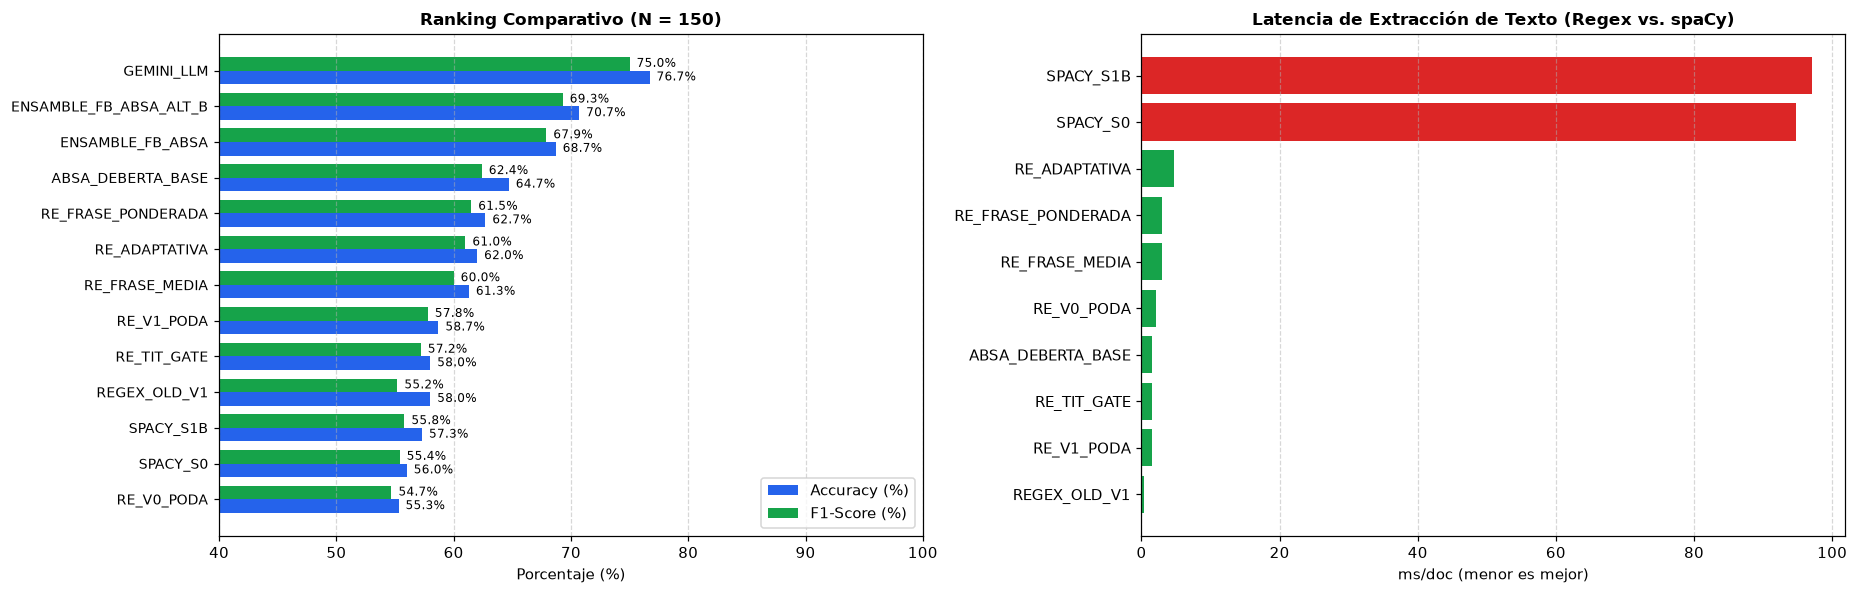

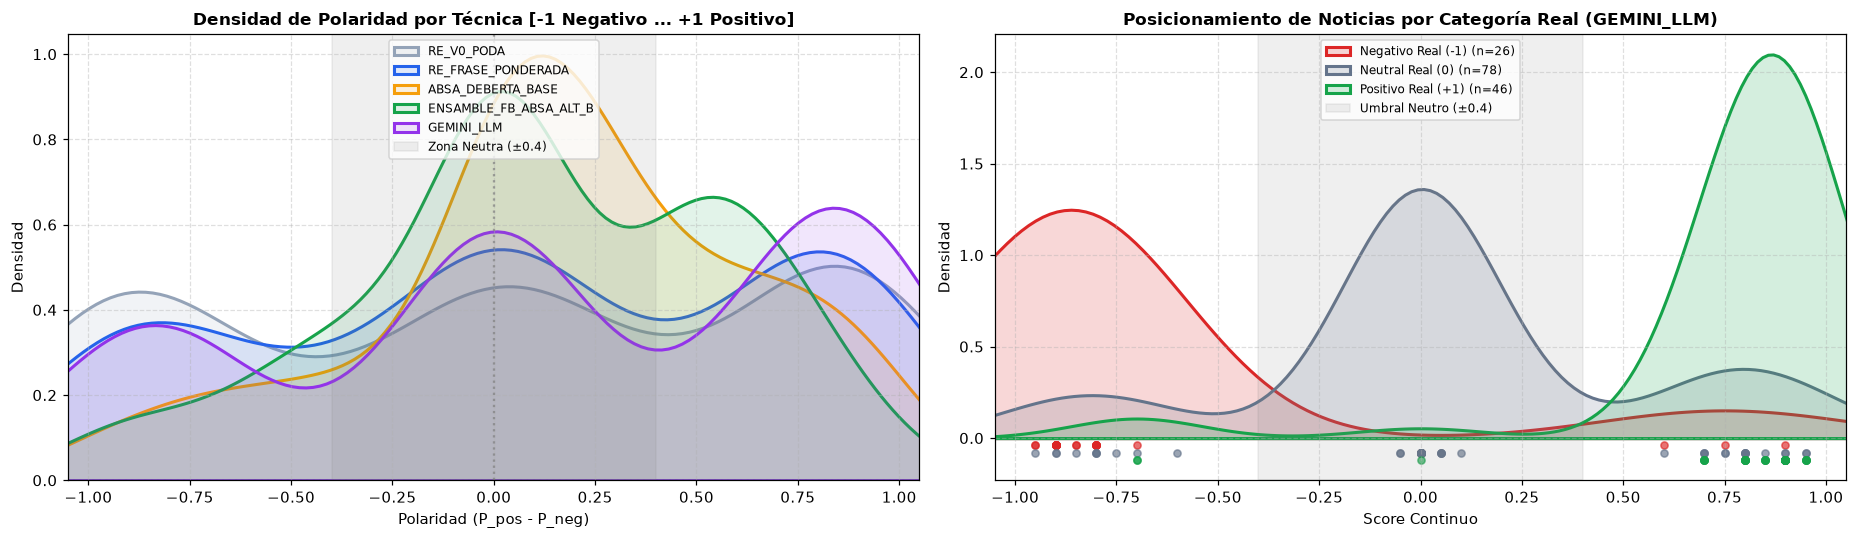

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), dpi=110)

# Panel 1: Ranking horizontal de Accuracy y F1-Score
if "df_kpis_out" in locals():
    df_rank = df_kpis_out.sort_values("Accuracy", ascending=True)
    y_pos = np.arange(len(df_rank))
    h = 0.38
    axes[0].barh(y_pos - h/2, df_rank["Accuracy"] * 100, h, label="Accuracy (%)", color="#2563eb")
    axes[0].barh(y_pos + h/2, df_rank["F1-Score"] * 100, h, label="F1-Score (%)", color="#16a34a")
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(df_rank["Estrategia"], fontsize=9)
    axes[0].set_xlabel("Porcentaje (%)")
    axes[0].set_title("Ranking Comparativo (N = 150)", fontsize=11, fontweight="bold")
    axes[0].set_xlim(40, 100)
    axes[0].legend(loc="lower right")
    axes[0].grid(axis="x", linestyle="--", alpha=0.5)
    for i, (acc_v, f1_v) in enumerate(zip(df_rank["Accuracy"] * 100, df_rank["F1-Score"] * 100)):
        axes[0].text(acc_v + 0.6, i - h/2, f"{acc_v:.1f}%", va="center", fontsize=8)
        axes[0].text(f1_v + 0.6, i + h/2, f"{f1_v:.1f}%", va="center", fontsize=8)

# Panel 2: Velocidad de extracción (ms/doc)
df_ext = df_resumen.sort_values("Extracción (ms/doc)", ascending=True)
colors_ext = ["#dc2626" if "SPACY" in v else "#16a34a" for v in df_ext["Variante"]]
axes[1].barh(df_ext["Variante"], df_ext["Extracción (ms/doc)"], color=colors_ext)
axes[1].set_title("Latencia de Extracción de Texto (Regex vs. spaCy)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("ms/doc (menor es mejor)")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Figura 2: Densidad de Polaridad Continua [-1, +1] y posicionamiento por categoría real
fig2, (ax_est, ax_gt) = plt.subplots(1, 2, figsize=(17, 5), dpi=110)

colores_est = {
    "RE_V0_PODA":             "#94a3b8",
    "RE_FRASE_PONDERADA":     "#2563eb",
    "ABSA_DEBERTA_BASE":      "#f59e0b",
    "ENSAMBLE_FB_ABSA_ALT_B": "#16a34a",
    "GEMINI_LLM":             "#9333ea",
}
for nombre, col in colores_est.items():
    if nombre in res:
        sns.kdeplot(res[nombre]["sentiment"], ax=ax_est, label=nombre, color=col, fill=True, alpha=0.12, linewidth=2)

ax_est.axvspan(-UMBRAL_NEUTRO, UMBRAL_NEUTRO, color="gray", alpha=0.12, label=f"Zona Neutra (±{UMBRAL_NEUTRO})")
ax_est.axvline(0, color="gray", linestyle=":", alpha=0.7)
ax_est.set_xlim(-1.05, 1.05)
ax_est.set_title("Densidad de Polaridad por Técnica [-1 Negativo ... +1 Positivo]", fontsize=11, fontweight="bold")
ax_est.set_xlabel("Polaridad (P_pos - P_neg)")
ax_est.set_ylabel("Densidad")
ax_est.legend(loc="upper center", fontsize=8)
ax_est.grid(True, linestyle="--", alpha=0.4)

if df_gt is not None and df_gt["etiqueta_manual"].notna().all():
    target_viz = "GEMINI_LLM" if "GEMINI_LLM" in res else "ENSAMBLE_FB_ABSA_ALT_B"
    mapa_lbl = {-1: ("Negativo Real (-1)", "#dc2626"), 0: ("Neutral Real (0)", "#64748b"), 1: ("Positivo Real (+1)", "#16a34a")}
    df_viz = df_gt.copy()
    df_viz["sent_target"] = res[target_viz]["sentiment"].values
    for val, (etiq, c_lbl) in mapa_lbl.items():
        sub = df_viz[df_viz["etiqueta_manual"].astype(int) == val]["sent_target"]
        if len(sub) > 1 and sub.std() > 1e-6:
            sns.kdeplot(sub, ax=ax_gt, label=f"{etiq} (n={len(sub)})", color=c_lbl, fill=True, alpha=0.18, linewidth=2)
        ax_gt.scatter(sub, np.full(len(sub), -0.04 * (val + 2)), color=c_lbl, alpha=0.65, s=22)

    ax_gt.axvspan(-UMBRAL_NEUTRO, UMBRAL_NEUTRO, color="gray", alpha=0.12, label=f"Umbral Neutro (±{UMBRAL_NEUTRO})")
    ax_gt.set_xlim(-1.05, 1.05)
    ax_gt.set_title(f"Posicionamiento de Noticias por Categoría Real ({target_viz})", fontsize=11, fontweight="bold")
    ax_gt.set_xlabel("Score Continuo")
    ax_gt.set_ylabel("Densidad")
    ax_gt.legend(loc="upper center", fontsize=8)
    ax_gt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
res["GEMINI_31_LITE"] = await correr_llm_lotes("gemini-3.1-flash-lite", batch_size=15, pause_s=4.5, es_gemma=False)

y_true = df_gt["etiqueta_manual"].astype(int).to_numpy()
rows_cmp = []
for nom, yp in [
    ("GEMINI_31_LITE (150)", res["GEMINI_31_LITE"]["label"].astype(int).to_numpy()),
    ("ENSAMBLE_FB_ABSA_ALT_B", signo(res["ENSAMBLE_FB_ABSA_ALT_B"]["sentiment"].to_numpy(), 0.35)),
]:
    k, _ = evaluar_ground_truth(y_true, yp, nom)
    rows_cmp.append(k)
display(pd.DataFrame(rows_cmp))

[gemini-3.1-flash-lite] En caché válidos: 0 | Pendientes: 150 (10 lotes)


  Lote 1/10 OK (15/15)
  Lote 2/10 OK (15/15)
  Lote 3/10 OK (15/15)
  Lote 4/10 OK (15/15)
  Lote 5/10 OK (15/15)
  Lote 6/10 OK (15/15)
  Lote 7/10 OK (15/15)
  Lote 8/10 OK (15/15)
  Lote 9/10 OK (15/15)
  Lote 10/10 OK (15/15)


,Familia,Estrategia,Accuracy,Precision (Macro),Recall (Macro),F1-Score,F2-Score (β=2),Rec Pos (+1),Rec Neu (0),Rec Neg (-1),Falsos Neutros,Inversiones
0,Otra,GEMINI_31_LITE (150),0.813,0.794,0.825,0.806,0.817,0.783,0.808,0.885,10,3
1,3. Aspecto (ABSA),ENSAMBLE_FB_ABSA_ALT_B,0.707,0.694,0.697,0.693,0.695,0.783,0.692,0.615,18,2
